In [ ]:
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
from sklearn.metrics import confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import copy
import time

SEED = 42
BATCH_SIZE = 128
EPOCHS = 10
LR = 0.001
WEIGHT_DECAY = 0.0001
MEAN = (0.4914, 0.4822, 0.4465)
STD = (0.2023, 0.1994, 0.2010)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

def set_seed():
    torch.manual_seed(SEED)
    np.random.seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

def synchronize():
    if device.type == "cuda":
        torch.cuda.synchronize()

set_seed()
transform = transforms.Compose([
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)
])
all_train = datasets.CIFAR10("data", train=True, download=True, transform=transform)
indices = np.random.RandomState(SEED).permutation(len(all_train)).tolist()
train_data = Subset(all_train, indices[:45000])
val_data = Subset(all_train, indices[45000:])
train_eval_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=False)
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False)
classes = all_train.classes

def make_train_loader():
    return DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True,
                      generator=torch.Generator().manual_seed(SEED))

probe_images, probe_labels = next(iter(train_eval_loader))
probe_images = probe_images.to(device)
probe_labels = probe_labels.to(device)
print("Train:", len(train_data), "Validation:", len(val_data))
print("Fixed gradient batch:", list(probe_images.shape))


Device: cuda
GPU: Tesla T4


100%|██████████| 170M/170M [26:37<00:00, 107kB/s]


Train: 45000 Validation: 5000
Fixed gradient batch: [128, 3, 32, 32]


In [ ]:
class ConvPairBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1, use_shortcut=False):
        super(ConvPairBlock, self).__init__()
        self.use_shortcut = use_shortcut
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU()
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)
        if use_shortcut:
            if stride != 1 or in_channels != out_channels:
                self.shortcut = nn.Conv2d(in_channels, out_channels, 1, stride=stride, bias=False)
            else:
                self.shortcut = nn.Identity()

    def forward(self, x):
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.use_shortcut:
            out = out + self.shortcut(x)
        return self.relu(out)

class PlainOrResNet(nn.Module):
    def __init__(self, use_shortcut=False):
        super(PlainOrResNet, self).__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1, bias=False),
            nn.BatchNorm2d(16), nn.ReLU()
        )
        self.stage1 = nn.Sequential(
            ConvPairBlock(16, 16, use_shortcut=use_shortcut),
            ConvPairBlock(16, 16, use_shortcut=use_shortcut)
        )
        self.stage2 = nn.Sequential(
            ConvPairBlock(16, 32, stride=2, use_shortcut=use_shortcut),
            ConvPairBlock(32, 32, use_shortcut=use_shortcut)
        )
        self.stage3 = nn.Sequential(
            ConvPairBlock(32, 64, stride=2, use_shortcut=use_shortcut),
            ConvPairBlock(64, 64, use_shortcut=use_shortcut)
        )
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.flatten = nn.Flatten()
        self.fc = nn.Linear(64, 10)

    def forward(self, x):
        x = self.stem(x)
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        x = self.gap(x)
        x = self.flatten(x)
        return self.fc(x)


In [ ]:
class DenseLayer(nn.Module):
    def __init__(self, in_channels, growth_rate):
        super(DenseLayer, self).__init__()
        self.bn = nn.BatchNorm2d(in_channels)
        self.relu = nn.ReLU()
        self.conv = nn.Conv2d(in_channels, growth_rate, 3, padding=1, bias=False)

    def forward(self, x):
        new_features = self.conv(self.relu(self.bn(x)))
        return torch.cat([x, new_features], dim=1)

class DenseBlock(nn.Module):
    def __init__(self, in_channels, growth_rate):
        super(DenseBlock, self).__init__()
        self.layers = nn.Sequential(
            DenseLayer(in_channels, growth_rate),
            DenseLayer(in_channels + growth_rate, growth_rate),
            DenseLayer(in_channels + 2 * growth_rate, growth_rate),
            DenseLayer(in_channels + 3 * growth_rate, growth_rate)
        )

    def forward(self, x):
        return self.layers(x)

class Transition(nn.Module):
    def __init__(self, in_channels):
        super(Transition, self).__init__()
        self.bn = nn.BatchNorm2d(in_channels)
        self.relu = nn.ReLU()
        self.conv = nn.Conv2d(in_channels, in_channels // 2, 1, bias=False)
        self.pool = nn.AvgPool2d(2)

    def forward(self, x):
        x = self.conv(self.relu(self.bn(x)))
        return self.pool(x)

class DenseNetMini(nn.Module):
    def __init__(self, growth_rate):
        super(DenseNetMini, self).__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, 24, 3, padding=1, bias=False),
            nn.BatchNorm2d(24), nn.ReLU()
        )
        self.block1 = DenseBlock(24, growth_rate)
        channels1 = 24 + 4 * growth_rate
        self.transition1 = Transition(channels1)
        self.block2 = DenseBlock(channels1 // 2, growth_rate)
        channels2 = channels1 // 2 + 4 * growth_rate
        self.transition2 = Transition(channels2)
        self.block3 = DenseBlock(channels2 // 2, growth_rate)
        channels3 = channels2 // 2 + 4 * growth_rate
        self.head = nn.Sequential(
            nn.BatchNorm2d(channels3), nn.ReLU(),
            nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(channels3, 10)
        )

    def forward(self, x):
        x = self.stem(x)
        x = self.block1(x)
        x = self.transition1(x)
        x = self.block2(x)
        x = self.transition2(x)
        x = self.block3(x)
        return self.head(x)

MODEL_NAMES = ["PlainCNN", "ResNetMini", "DenseNet-k12", "DenseNet-k20"]

def make_model(name):
    if name == "PlainCNN":
        return PlainOrResNet(use_shortcut=False)
    if name == "ResNetMini":
        return PlainOrResNet(use_shortcut=True)
    if name == "DenseNet-k12":
        return DenseNetMini(12)
    if name == "DenseNet-k20":
        return DenseNetMini(20)
    raise ValueError(name)

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


In [ ]:
shape_rows = []
parameter_rows = []
for name in MODEL_NAMES:
    set_seed()
    model = make_model(name).to(device)
    model.eval()
    print("\n", name, "\n", model)
    with torch.no_grad():
        x = torch.zeros(2, 3, 32, 32).to(device)
        for layer_name, layer in model.named_children():
            x = layer(x)
            row = {"model": name, "layer": layer_name, "shape": list(x.shape)}
            shape_rows.append(row)
            print(row)
        assert list(x.shape) == [2, 10]
    row = {"model": name, "parameters": count_parameters(model),
           "eligible_under_180000": count_parameters(model) <= 180000}
    parameter_rows.append(row)
    print(row)
    if name == "ResNetMini":
        for stage_name in ["stage1", "stage2", "stage3"]:
            for i, block in enumerate(getattr(model, stage_name)):
                print(stage_name, "block", i+1, type(block.shortcut).__name__,
                      "shortcut parameters:", count_parameters(block.shortcut))
    del model



 PlainCNN 
 PlainOrResNet(
  (stem): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
  )
  (stage1): Sequential(
    (0): ConvPairBlock(
      (conv1): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU()
      (conv2): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): ConvPairBlock(
      (conv1): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU()
      (conv2): Conv2d(16, 16, ker

In [ ]:
block = ConvPairBlock(16, 32, stride=2, use_shortcut=True).to(device)
block.eval()
with torch.no_grad():
    x = torch.zeros(2, 16, 32, 32).to(device)
    main_output = block.bn2(block.conv2(block.relu(block.bn1(block.conv1(x)))))
    print("Input:", list(x.shape), "Main path:", list(main_output.shape))
    try:
        main_output + x
    except RuntimeError:
        print("Adding the unchanged input fails because channels and spatial sizes differ.")
    projected = block.shortcut(x)
    print("Projection:", list(projected.shape), "Block output:", list(block(x).shape))
    assert main_output.shape == projected.shape

dense_channel_rows = []
for growth_rate in [12, 20]:
    model = DenseNetMini(growth_rate).to(device)
    model.eval()
    with torch.no_grad():
        x = model.stem(torch.zeros(2, 3, 32, 32).to(device))
        print("\nGrowth rate:", growth_rate, "Stem:", list(x.shape))
        for block_index in [1, 2, 3]:
            block = getattr(model, "block" + str(block_index))
            for layer_index, layer in enumerate(block.layers):
                previous_channels = x.shape[1]
                x = layer(x)
                assert x.shape[1] == previous_channels + growth_rate
                row = {"growth_rate": growth_rate, "block": block_index,
                       "layer": layer_index+1, "shape": list(x.shape)}
                dense_channel_rows.append(row)
                print(row)
            if block_index < 3:
                previous_channels = x.shape[1]
                x = getattr(model, "transition" + str(block_index))(x)
                assert x.shape[1] == previous_channels // 2
                print("Transition", block_index, list(x.shape))
        assert list(model.head(x).shape) == [2, 10]
    del model


Input: [2, 16, 32, 32] Main path: [2, 32, 16, 16]
Adding the unchanged input fails because channels and spatial sizes differ.
Projection: [2, 32, 16, 16] Block output: [2, 32, 16, 16]

Growth rate: 12 Stem: [2, 24, 32, 32]
{'growth_rate': 12, 'block': 1, 'layer': 1, 'shape': [2, 36, 32, 32]}
{'growth_rate': 12, 'block': 1, 'layer': 2, 'shape': [2, 48, 32, 32]}
{'growth_rate': 12, 'block': 1, 'layer': 3, 'shape': [2, 60, 32, 32]}
{'growth_rate': 12, 'block': 1, 'layer': 4, 'shape': [2, 72, 32, 32]}
Transition 1 [2, 36, 16, 16]
{'growth_rate': 12, 'block': 2, 'layer': 1, 'shape': [2, 48, 16, 16]}
{'growth_rate': 12, 'block': 2, 'layer': 2, 'shape': [2, 60, 16, 16]}
{'growth_rate': 12, 'block': 2, 'layer': 3, 'shape': [2, 72, 16, 16]}
{'growth_rate': 12, 'block': 2, 'layer': 4, 'shape': [2, 84, 16, 16]}
Transition 2 [2, 42, 8, 8]
{'growth_rate': 12, 'block': 3, 'layer': 1, 'shape': [2, 54, 8, 8]}
{'growth_rate': 12, 'block': 3, 'layer': 2, 'shape': [2, 66, 8, 8]}
{'growth_rate': 12, 'bloc

In [ ]:
criterion = nn.CrossEntropyLoss()

def evaluate(model, loader):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            pred = model(x)
            total_loss += criterion(pred, y).item() * y.size(0)
            correct += (pred.argmax(1) == y).sum().item()
            total += y.size(0)
    return total_loss / total, correct / total

def measure_gradients(model, name, epoch):
    was_training = model.training
    model.eval()
    model.zero_grad()
    with torch.enable_grad():
        loss = criterion(model(probe_images), probe_labels)
        loss.backward()
    layers = {"Stem": model.stem[0], "Stage1": model.stage1[0].conv1,
              "Stage2": model.stage2[0].conv1, "Stage3": model.stage3[0].conv1}
    rows = []
    for layer_name, layer in layers.items():
        grad = layer.weight.grad
        row = {"model": name, "epoch": epoch, "layer": layer_name,
               "gradient_l2": grad.norm().item(),
               "gradient_rms": grad.pow(2).mean().sqrt().item()}
        rows.append(row)
        print(row)
    model.zero_grad()
    model.train(was_training)
    return rows

fixed_forward_batch = torch.zeros(BATCH_SIZE, 3, 32, 32).to(device)

def forward_time(model):
    model.eval()
    measurements = []
    with torch.inference_mode():
        for _ in range(10):
            model(fixed_forward_batch)
        synchronize()
        for _ in range(30):
            synchronize()
            start = time.perf_counter()
            model(fixed_forward_batch)
            synchronize()
            measurements.append((time.perf_counter() - start) * 1000)
    return float(np.median(measurements))

def train_model(name):
    set_seed()
    model = make_model(name).to(device)
    loader = make_train_loader()
    optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    gradient_rows = []
    if name in ["PlainCNN", "ResNetMini"]:
        gradient_rows.extend(measure_gradients(model, name, 0))
    best_loss = float("inf")
    best_epoch = 0
    best_state = None
    probe_seconds = 0.0
    synchronize()
    start = time.perf_counter()

    for epoch in range(EPOCHS):
        model.train()
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            loss = criterion(model(x), y)
            loss.backward()
            optimizer.step()

        train_loss, train_acc = evaluate(model, train_eval_loader)
        val_loss, val_acc = evaluate(model, val_loader)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        if val_loss < best_loss:
            best_loss = val_loss
            best_epoch = epoch+1
            best_state = copy.deepcopy(model.state_dict())

        print(f"{name} Epoch {epoch+1:02d}/{EPOCHS} | Train Loss {train_loss:.4f} Acc {train_acc:.4f} | Val Loss {val_loss:.4f} Acc {val_acc:.4f}")
        if name in ["PlainCNN", "ResNetMini"] and epoch+1 in [5, 10]:
            synchronize()
            probe_start = time.perf_counter()
            gradient_rows.extend(measure_gradients(model, name, epoch+1))
            synchronize()
            probe_seconds += time.perf_counter() - probe_start

    synchronize()
    seconds = time.perf_counter() - start - probe_seconds
    model.load_state_dict(best_state)
    model.eval()
    maximum_acc = max(history["val_acc"])
    summary = {"model": name, "parameters": count_parameters(model),
               "best_loss_epoch": best_epoch, "validation_loss": best_loss,
               "checkpoint_validation_accuracy": history["val_acc"][best_epoch-1],
               "checkpoint_train_accuracy": history["train_acc"][best_epoch-1],
               "maximum_validation_accuracy": maximum_acc,
               "maximum_accuracy_epoch": history["val_acc"].index(maximum_acc)+1,
               "training_and_evaluation_seconds": seconds,
               "median_forward_ms": forward_time(model)}
    print(summary)
    return {"model": model, "history": history, "summary": summary, "gradients": gradient_rows}


In [ ]:
results = {}
for name in MODEL_NAMES:
    results[name] = train_model(name)


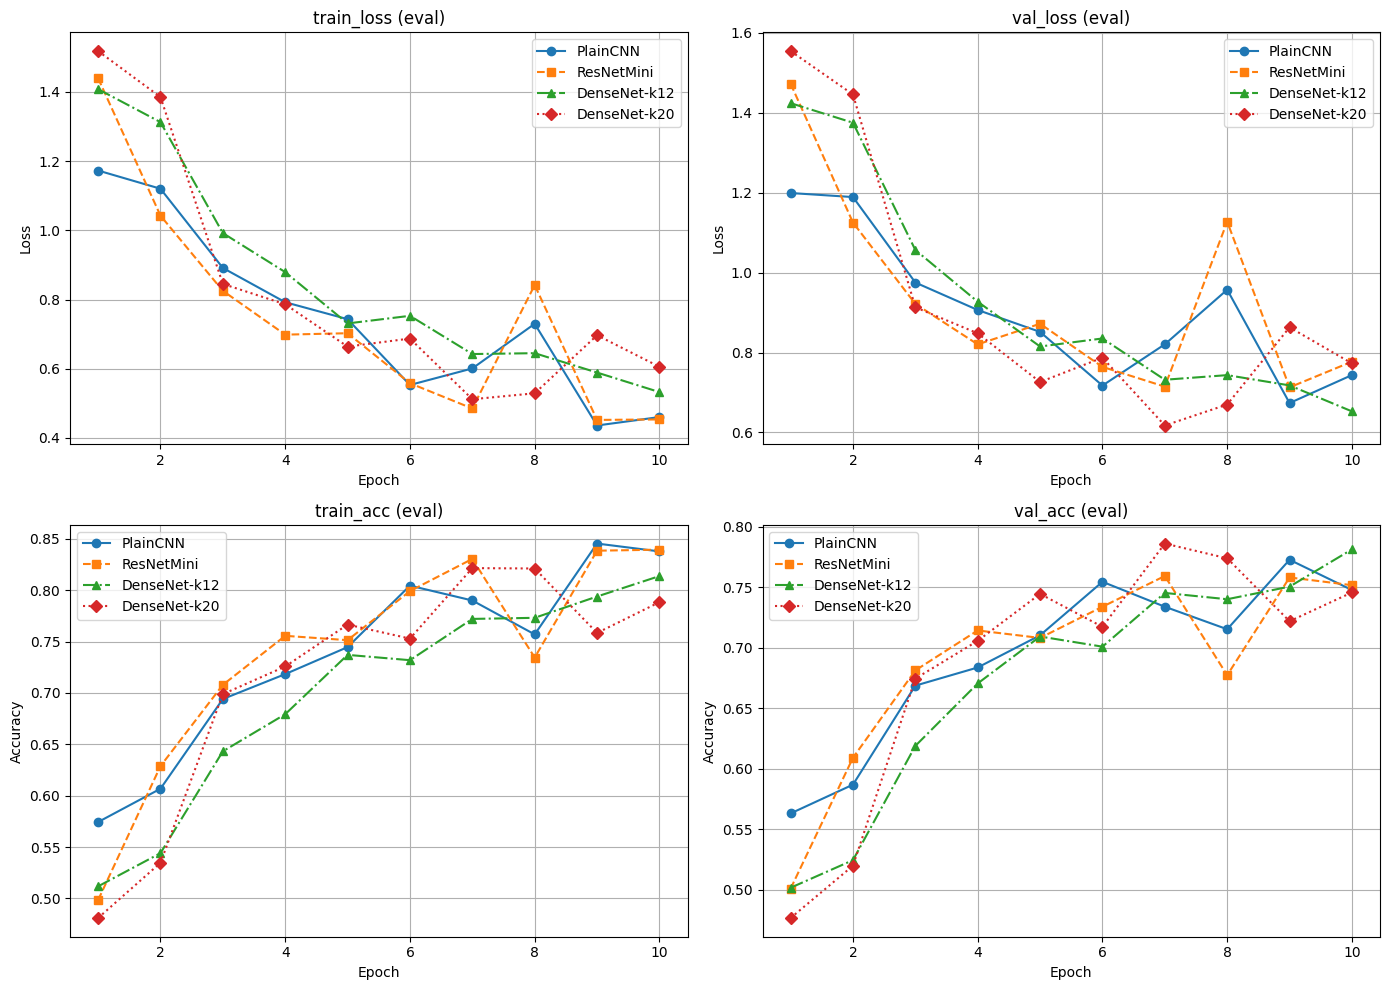

PlainCNN        | Params 172506 | Val Loss 0.6737 at epoch  9 | Checkpoint Acc 77.28% | Max Acc 77.28% at epoch  9 | Time 254.25s | Forward 6.049ms
ResNetMini      | Params 175066 | Val Loss 0.7130 at epoch  9 | Checkpoint Acc 75.82% | Max Acc 75.94% at epoch  7 | Time 251.61s | Forward 5.261ms
DenseNet-k12    | Params  76858 | Val Loss 0.6528 at epoch 10 | Checkpoint Acc 78.14% | Max Acc 78.14% at epoch 10 | Time 276.73s | Forward 8.513ms
DenseNet-k20    | Params 185946 | Val Loss 0.6175 at epoch  7 | Checkpoint Acc 78.62% | Max Acc 78.62% at epoch  7 | Time 315.19s | Forward 11.517ms
ResNet minus Plain checkpoint accuracy (percentage points): -1.4600000000000057
ResNet minus Plain parameters: 2560


In [ ]:
plt.figure(figsize=(14, 10))
styles = ["-", "--", "-.", ":"]
markers = ["o", "s", "^", "D"]
for panel, metric in enumerate(["train_loss", "val_loss", "train_acc", "val_acc"]):
    plt.subplot(2, 2, panel+1)
    for i, name in enumerate(MODEL_NAMES):
        plt.plot(range(1, EPOCHS+1), results[name]["history"][metric],
                 linestyle=styles[i], marker=markers[i], label=name)
    plt.xlabel("Epoch")
    plt.ylabel("Loss" if "loss" in metric else "Accuracy")
    plt.title(metric + " (eval)")
    plt.legend()
    plt.grid(True)
plt.tight_layout()
plt.show()
plt.close()

summary_rows = [results[name]["summary"] for name in MODEL_NAMES]
for row in summary_rows:
    print(f"{row['model']:15} | Params {row['parameters']:6} | Val Loss {row['validation_loss']:.4f} at epoch {row['best_loss_epoch']:2} | Checkpoint Acc {100*row['checkpoint_validation_accuracy']:.2f}% | Max Acc {100*row['maximum_validation_accuracy']:.2f}% at epoch {row['maximum_accuracy_epoch']:2} | Time {row['training_and_evaluation_seconds']:.2f}s | Forward {row['median_forward_ms']:.3f}ms")

plain = results["PlainCNN"]["summary"]
resnet = results["ResNetMini"]["summary"]
print("ResNet minus Plain checkpoint accuracy (percentage points):",
      100*(resnet["checkpoint_validation_accuracy"] - plain["checkpoint_validation_accuracy"]))
print("ResNet minus Plain parameters:", resnet["parameters"] - plain["parameters"])


Model       Epoch Layer     Gradient L2       Gradient RMS
PlainCNN        0 Stem        1.44623e-06    6.95815e-08
PlainCNN        0 Stage1      3.20972e-06    6.68692e-08
PlainCNN        0 Stage2      1.68954e-06    2.48893e-08
PlainCNN        0 Stage3      2.95185e-06    2.17424e-08
PlainCNN        5 Stem            3.24722       0.156232
PlainCNN        5 Stage1          3.02928        0.06311
PlainCNN        5 Stage2          3.67505      0.0541387
PlainCNN        5 Stage3          2.47527      0.0182321
PlainCNN       10 Stem            2.42554       0.116699
PlainCNN       10 Stage1          1.67976      0.0349951
PlainCNN       10 Stage2          2.34584      0.0345576
PlainCNN       10 Stage3          2.05914       0.015167
ResNetMini      0 Stem           0.024175     0.00116312
ResNetMini      0 Stage1        0.0102158     0.00021283
ResNetMini      0 Stage2          0.02395    0.000352817
ResNetMini      0 Stage3        0.0300465    0.000221314
ResNetMini      5 Stem       

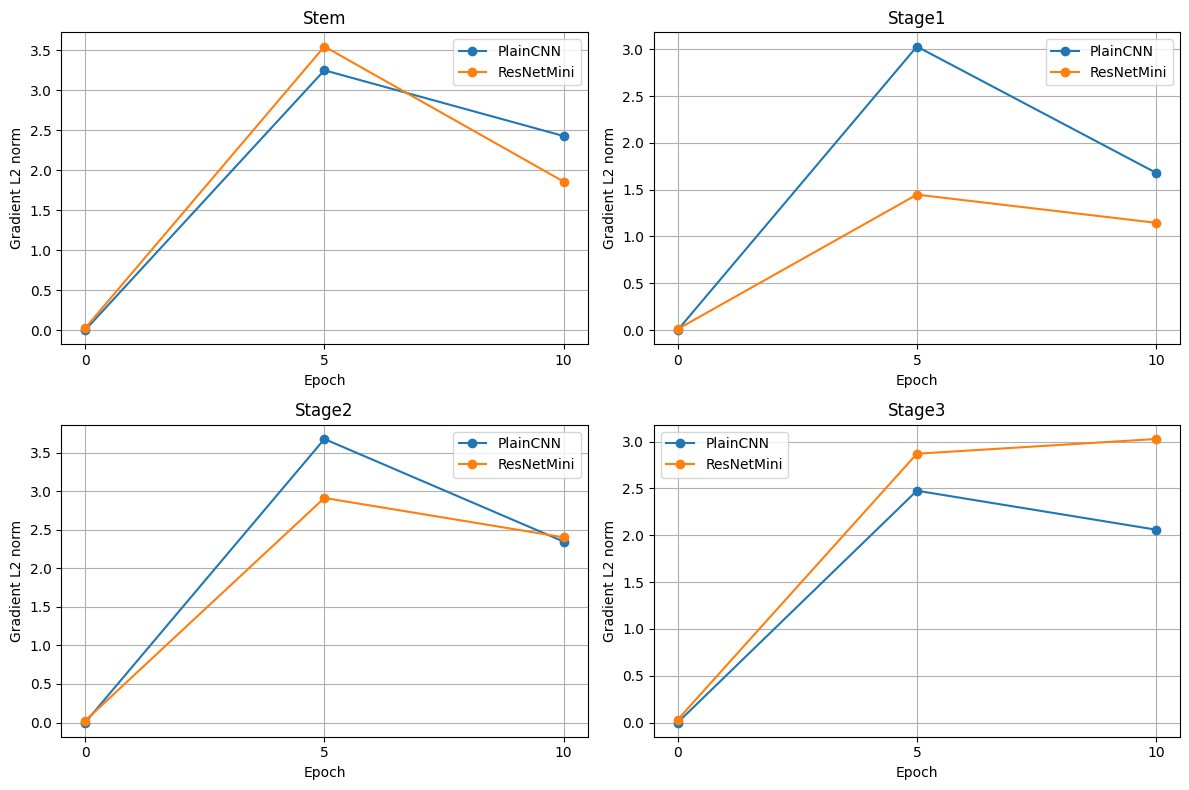

In [ ]:
all_gradients = results["PlainCNN"]["gradients"] + results["ResNetMini"]["gradients"]
print("Model       Epoch Layer     Gradient L2       Gradient RMS")
for row in all_gradients:
    print(f"{row['model']:11} {row['epoch']:5} {row['layer']:8} {row['gradient_l2']:14.6g} {row['gradient_rms']:14.6g}")

plt.figure(figsize=(12, 8))
for panel, layer_name in enumerate(["Stem", "Stage1", "Stage2", "Stage3"]):
    plt.subplot(2, 2, panel+1)
    for name in ["PlainCNN", "ResNetMini"]:
        rows = [r for r in all_gradients if r["model"] == name and r["layer"] == layer_name]
        plt.plot([r["epoch"] for r in rows], [r["gradient_l2"] for r in rows], marker="o", label=name)
    plt.xticks([0, 5, 10])
    plt.xlabel("Epoch")
    plt.ylabel("Gradient L2 norm")
    plt.title(layer_name)
    plt.grid(True)
    plt.legend()
plt.tight_layout()
plt.show()
plt.close()


{'model': 'ResNetMini', 'class': 'airplane', 'count': 510, 'errors': 100, 'accuracy': 0.803921568627451}
{'model': 'ResNetMini', 'class': 'automobile', 'count': 487, 'errors': 56, 'accuracy': 0.8850102669404517}
{'model': 'ResNetMini', 'class': 'bird', 'count': 502, 'errors': 97, 'accuracy': 0.8067729083665338}
{'model': 'ResNetMini', 'class': 'cat', 'count': 474, 'errors': 214, 'accuracy': 0.5485232067510548}
{'model': 'ResNetMini', 'class': 'deer', 'count': 524, 'errors': 129, 'accuracy': 0.7538167938931297}
{'model': 'ResNetMini', 'class': 'dog', 'count': 503, 'errors': 170, 'accuracy': 0.6620278330019881}
{'model': 'ResNetMini', 'class': 'frog', 'count': 505, 'errors': 76, 'accuracy': 0.8495049504950495}
{'model': 'ResNetMini', 'class': 'horse', 'count': 534, 'errors': 135, 'accuracy': 0.7471910112359551}
{'model': 'ResNetMini', 'class': 'ship', 'count': 499, 'errors': 52, 'accuracy': 0.8957915831663327}
{'model': 'ResNetMini', 'class': 'truck', 'count': 462, 'errors': 180, 'accura

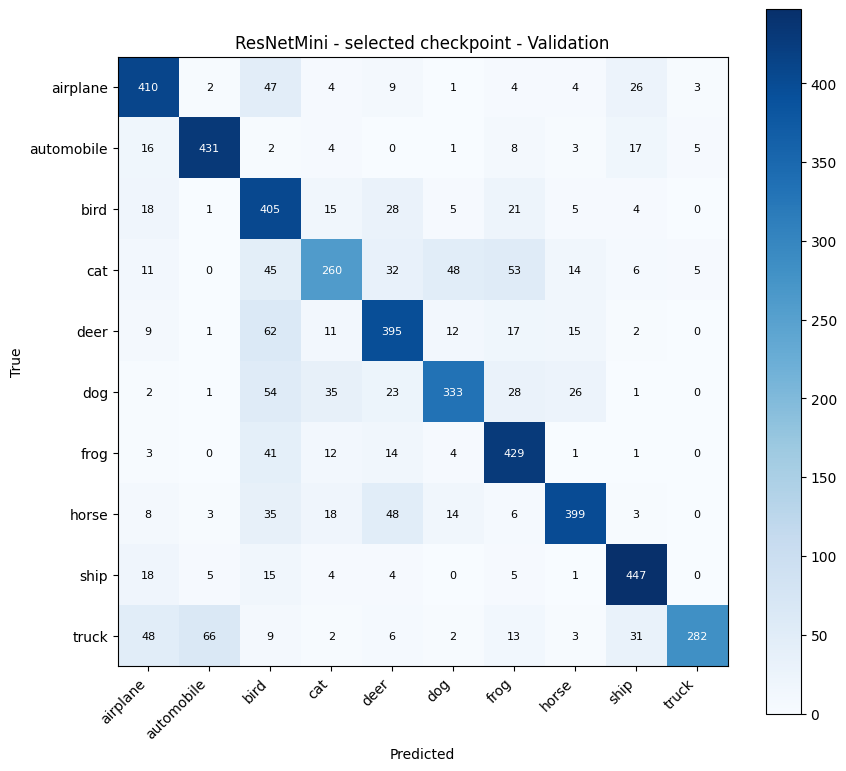

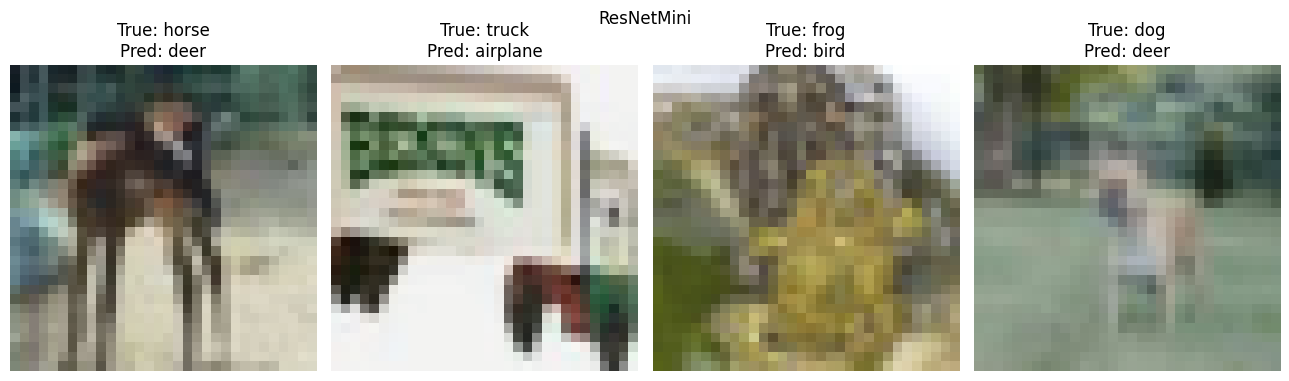

{'model': 'DenseNet-k20', 'class': 'airplane', 'count': 510, 'errors': 65, 'accuracy': 0.8725490196078431}
{'model': 'DenseNet-k20', 'class': 'automobile', 'count': 487, 'errors': 53, 'accuracy': 0.891170431211499}
{'model': 'DenseNet-k20', 'class': 'bird', 'count': 502, 'errors': 184, 'accuracy': 0.6334661354581673}
{'model': 'DenseNet-k20', 'class': 'cat', 'count': 474, 'errors': 96, 'accuracy': 0.7974683544303798}
{'model': 'DenseNet-k20', 'class': 'deer', 'count': 524, 'errors': 135, 'accuracy': 0.7423664122137404}
{'model': 'DenseNet-k20', 'class': 'dog', 'count': 503, 'errors': 222, 'accuracy': 0.558648111332008}
{'model': 'DenseNet-k20', 'class': 'frog', 'count': 505, 'errors': 76, 'accuracy': 0.8495049504950495}
{'model': 'DenseNet-k20', 'class': 'horse', 'count': 534, 'errors': 89, 'accuracy': 0.8333333333333334}
{'model': 'DenseNet-k20', 'class': 'ship', 'count': 499, 'errors': 81, 'accuracy': 0.8376753507014028}
{'model': 'DenseNet-k20', 'class': 'truck', 'count': 462, 'erro

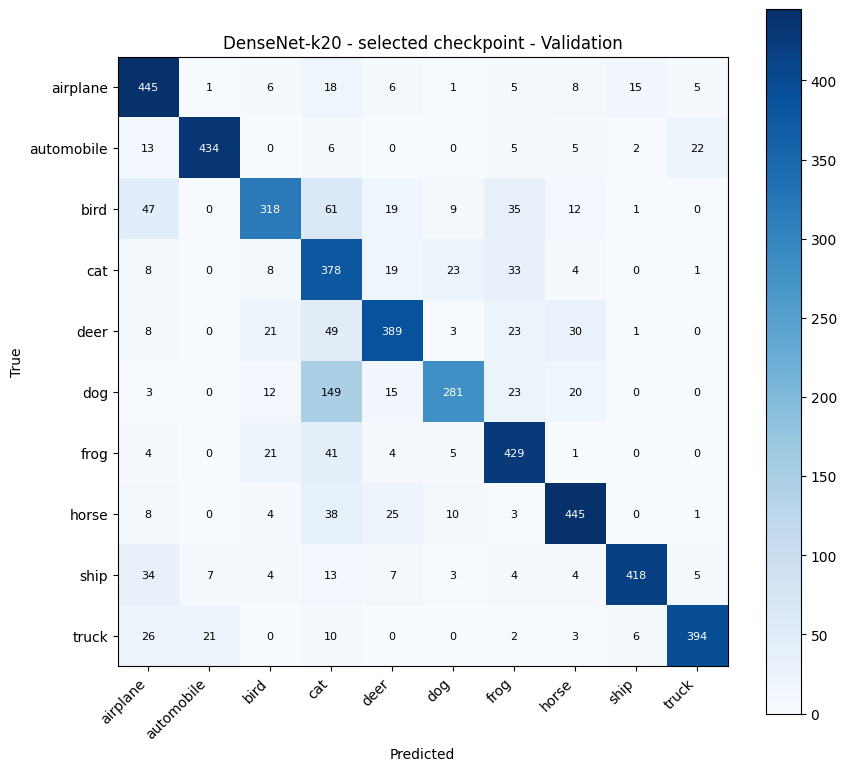

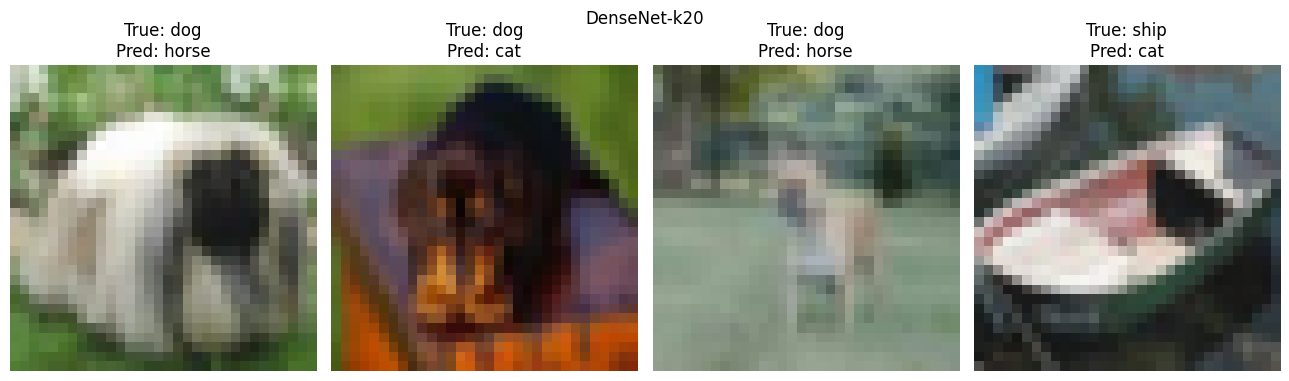

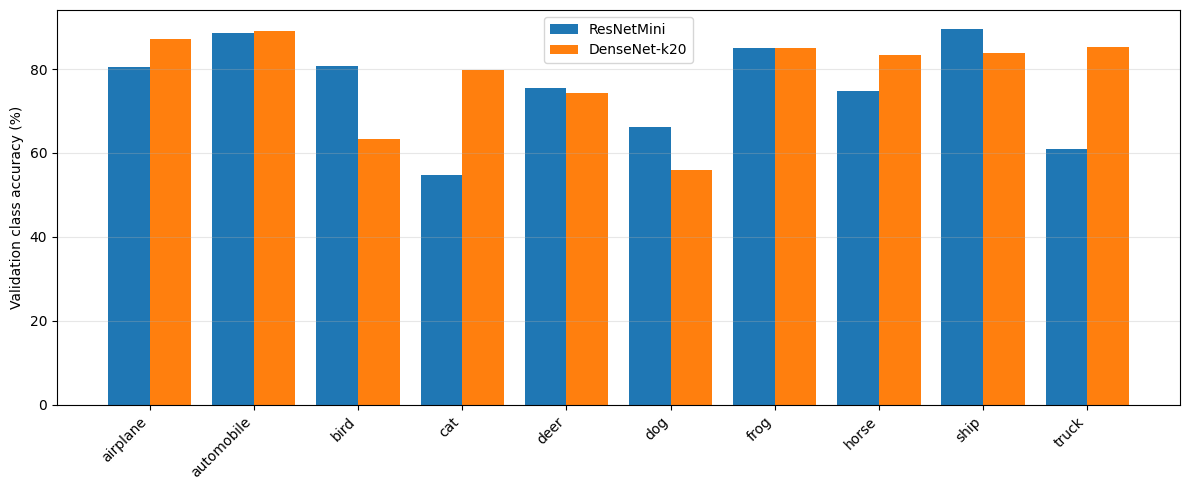

In [ ]:
def predictions_and_errors(model):
    model.eval()
    labels, predictions, examples = [], [], []
    with torch.no_grad():
        for x, y in val_loader:
            pred = model(x.to(device)).argmax(1).cpu()
            labels.extend(y.tolist())
            predictions.extend(pred.tolist())
            for i in range(len(y)):
                if pred[i].item() != y[i].item() and len(examples) < 4:
                    examples.append((x[i], y[i].item(), pred[i].item()))
    return np.array(labels), np.array(predictions), examples

class_rows = []
class_accuracies = {}
error_summaries = {}
for name in ["ResNetMini", "DenseNet-k20"]:
    model = results[name]["model"]
    labels, predictions, examples = predictions_and_errors(model)
    cm = confusion_matrix(labels, predictions, labels=list(range(10)))
    counts = cm.sum(axis=1)
    correct = cm.diagonal()
    errors = counts - correct
    class_acc = correct / counts
    class_accuracies[name] = class_acc
    for i in range(10):
        row = {"model": name, "class": classes[i], "count": int(counts[i]),
               "errors": int(errors[i]), "accuracy": float(class_acc[i])}
        class_rows.append(row)
        print(row)
    top = np.argsort(-errors)[:2]
    error_summaries[name] = {
        "top_two_error_classes": [{"class": classes[i], "errors": int(errors[i])} for i in top],
        "shown_examples": [{"true": classes[y], "predicted": classes[p]} for image, y, p in examples]
    }
    print(name, error_summaries[name])
    print("Confusion matrix (rows=true, columns=predicted):\n", cm)

    plt.figure(figsize=(9, 8))
    plt.imshow(cm, cmap="Blues")
    plt.colorbar()
    plt.xticks(range(10), classes, rotation=45, ha="right")
    plt.yticks(range(10), classes)
    for i in range(10):
        for j in range(10):
            plt.text(j, i, str(cm[i,j]), ha="center", va="center", fontsize=8,
                     color="white" if cm[i,j] > cm.max()/2 else "black")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title(name + " - selected checkpoint - Validation")
    plt.tight_layout()
    plt.show()
    plt.close()

    if examples:
        plt.figure(figsize=(13, 4))
        for i, (image, label, prediction) in enumerate(examples):
            image = image.permute(1, 2, 0).numpy()
            image = np.clip(image * np.array(STD) + np.array(MEAN), 0, 1)
            plt.subplot(1, len(examples), i+1)
            plt.imshow(image)
            plt.title("True: " + classes[label] + "\nPred: " + classes[prediction])
            plt.axis("off")
        plt.suptitle(name)
        plt.tight_layout()
        plt.show()
        plt.close()

x = np.arange(10)
plt.figure(figsize=(12, 5))
plt.bar(x-0.2, 100*class_accuracies["ResNetMini"], width=0.4, label="ResNetMini")
plt.bar(x+0.2, 100*class_accuracies["DenseNet-k20"], width=0.4, label="DenseNet-k20")
plt.xticks(x, classes, rotation=45, ha="right")
plt.ylabel("Validation class accuracy (%)")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
plt.close()


In [ ]:
eligible = [row for row in summary_rows if row["parameters"] <= 180000]
assert eligible
best_accuracy = max(row["checkpoint_validation_accuracy"] for row in eligible)
close_models = [row for row in eligible
                if best_accuracy - row["checkpoint_validation_accuracy"] <= 0.005 + 1e-12]
chosen = min(close_models, key=lambda row: (row["median_forward_ms"], row["parameters"]))
selected_name = chosen["model"]
selected_model = results[selected_name]["model"]
print("Eligible models:", [r["model"] for r in eligible])
print("Within 0.5 percentage points of best:", [r["model"] for r in close_models])
print("Selected model:", chosen)


Eligible models: ['PlainCNN', 'ResNetMini', 'DenseNet-k12']
Within 0.5 percentage points of best: ['DenseNet-k12']
Selected model: {'model': 'DenseNet-k12', 'parameters': 76858, 'best_loss_epoch': 10, 'validation_loss': 0.652834235215187, 'checkpoint_validation_accuracy': 0.7814, 'checkpoint_train_accuracy': 0.8138, 'maximum_validation_accuracy': 0.7814, 'maximum_accuracy_epoch': 10, 'training_and_evaluation_seconds': 276.7310801509998, 'median_forward_ms': 8.51289449997239}


In [ ]:
if "final_test_result_ex3" not in globals():
    test_data = datasets.CIFAR10("data", train=False, download=True, transform=transform)
    test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False)
    test_loss, test_acc = evaluate(selected_model, test_loader)
    final_test_result_ex3 = {
        "model": selected_name, "seed": SEED,
        "checkpoint_epoch": chosen["best_loss_epoch"],
        "test_loss": test_loss, "test_accuracy": test_acc
    }
print(final_test_result_ex3)


{'model': 'DenseNet-k12', 'seed': 42, 'checkpoint_epoch': 10, 'test_loss': 0.6604626993179321, 'test_accuracy': 0.7734}
